In [6]:
import matplotlib.pyplot as plt
import numpy as np

from nonconvex_regression import clean_data, lad, lp_irls, ols

plt.style.use("seaborn-v0_8-whitegrid")

In [7]:
n = 1000
beta = np.array([1.0, 1.0])
epsilon = 1
x_min, x_max = -2, 2
lp = 0.2
eps = 1e-3

points_clean = clean_data(n, beta, epsilon, x_min, x_max)

x_line = np.linspace(x_min, x_max, 200)
true_line = beta[0] + beta[1] * x_line

In [8]:
beta_ols = ols(points_clean[:, 0:1], points_clean[:, 1])
beta_lad = lad(points_clean[:, 0:1], points_clean[:, 1])
beta_lp = lp_irls(points_clean[:, 0:1], points_clean[:, 1], lp, eps)

ols_line = beta_ols[0] + beta_ols[1] * x_line
lad_line = beta_lad[0] + beta_lad[1] * x_line
lp_line = beta_lp[0] + beta_lp[1] * x_line

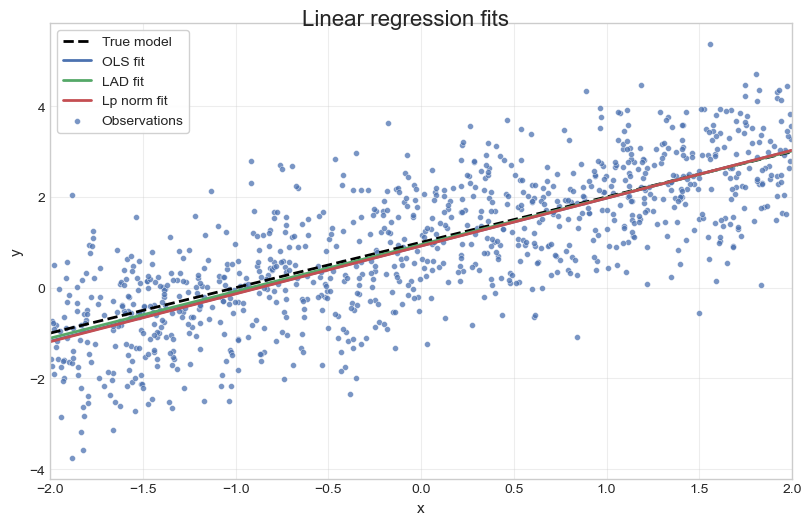

In [9]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
fig.suptitle("Linear regression fits", fontsize=16, y=1.02)

ax.plot(x_line, true_line, color="black", lw=2, ls="--", label="True model")
ax.plot(x_line, ols_line, color="#4C72B0", lw=2, label="OLS fit")
ax.plot(x_line, lad_line, color="#55A868", lw=2, label="LAD fit")
ax.plot(x_line, lp_line, color="#C44E52", lw=2, label="Lp norm fit")

ax.scatter(
    points_clean[:, 0],
    points_clean[:, 1],
    s=18,
    alpha=0.75,
    c="#4C72B0",
    edgecolors="white",
    linewidths=0.35,
    label="Observations",
)

ax.set_xlim(x_min, x_max)
ax.set_xlabel("x", fontsize=11)
ax.set_ylabel("y", fontsize=11)
ax.grid(alpha=0.35)
ax.legend(frameon=True, fancybox=True, framealpha=0.9)

plt.show()

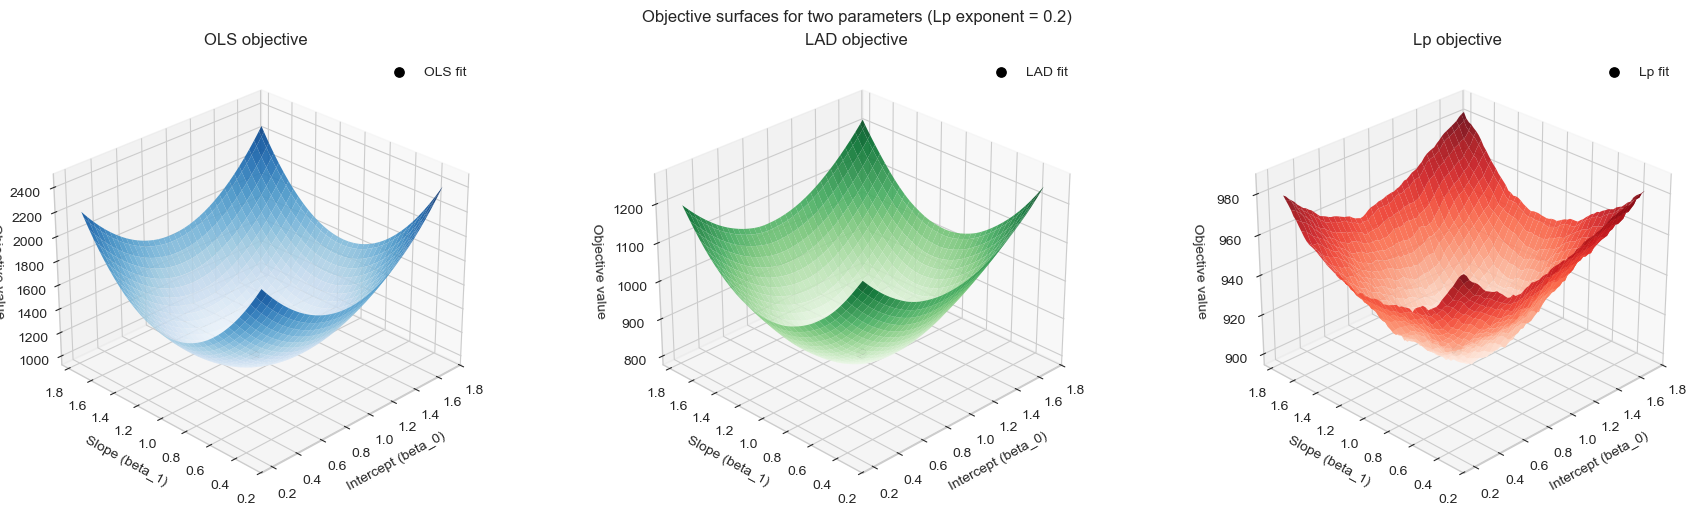

In [10]:
coefficient_values = np.vstack((beta, beta_ols, beta_lad, beta_lp))
coefficient_margin = 0.5 + 0.2 * np.maximum(1.0, np.ptp(coefficient_values, axis=0))
intercept_range = np.linspace(
    coefficient_values[:, 0].min() - coefficient_margin[0],
    coefficient_values[:, 0].max() + coefficient_margin[0],
    70,
)
slope_range = np.linspace(
    coefficient_values[:, 1].min() - coefficient_margin[1],
    coefficient_values[:, 1].max() + coefficient_margin[1],
    70,
)
intercept_grid, slope_grid = np.meshgrid(intercept_range, slope_range)

objective_surfaces = {
    "OLS": np.zeros_like(intercept_grid),
    "LAD": np.zeros_like(intercept_grid),
    "Lp": np.zeros_like(intercept_grid),
}
for x_value, y_value in points_clean:
    residual_grid = intercept_grid + slope_grid * x_value - y_value
    objective_surfaces["OLS"] += residual_grid**2
    objective_surfaces["LAD"] += np.abs(residual_grid)
    objective_surfaces["Lp"] += np.hypot(residual_grid, eps) ** lp

fit_coefficients = {"OLS": beta_ols, "LAD": beta_lad, "Lp": beta_lp}
residuals_at_fit = {
    name: coefficients[0] + coefficients[1] * points_clean[:, 0] - points_clean[:, 1]
    for name, coefficients in fit_coefficients.items()
}
fit_objectives = {
    "OLS": np.sum(residuals_at_fit["OLS"] ** 2),
    "LAD": np.sum(np.abs(residuals_at_fit["LAD"])),
    "Lp": np.sum(np.hypot(residuals_at_fit["Lp"], eps) ** lp),
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5),
    subplot_kw={"projection": "3d"},
    constrained_layout=True,
)
colormaps = {"OLS": "Blues", "LAD": "Greens", "Lp": "Reds"}
for ax, (name, surface) in zip(axes, objective_surfaces.items(), strict=False):
    ax.plot_surface(
        intercept_grid,
        slope_grid,
        surface,
        cmap=colormaps[name],
        edgecolor="none",
        alpha=0.9,
    )
    coefficients = fit_coefficients[name]
    ax.scatter(
        coefficients[0],
        coefficients[1],
        fit_objectives[name],
        color="black",
        s=45,
        label=f"{name} fit",
        depthshade=False,
    )
    ax.set_title(f"{name} objective")
    ax.set_xlabel("Intercept (beta_0)")
    ax.set_ylabel("Slope (beta_1)")
    ax.set_zlabel("Objective value")
    ax.view_init(elev=28, azim=-135)
    ax.legend()

fig.suptitle(f"Objective surfaces for two parameters (Lp exponent = {lp})")
plt.show()